In [27]:
# import libraries
import pandas as pd
import random as rnd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import requests
import logging

%matplotlib inline

# setting up pseudo-random numbers for python standard and numpy random module.
rng = np.random.default_rng(seed=1234)

### Download the file travel review ratings file and get into DataFrame

Data Source: https://archive.ics.uci.edu/dataset/485/tarvel+review+ratings

We have copied the google_review_ratings.csv to current directory.

#### Get the google_review_ratings.csv file

In [28]:
file_google_review= 'google_review_ratings.csv'

# Catch any exception reading file
try: 
    df_raw = pd.read_csv(f'{file_google_review}' ) 
except FileNotFoundError: # if file is not not found. 
    print(f"Error: The file '{file_google_review}' was not found.")

df_raw.head()

,User,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,Category 10,Category 11,Category 12,Category 13,Category 14,Category 15,Category 16,Category 17,Category 18,Category 19,Category 20,Category 21,Category 22,Category 23,Category 24,Unnamed: 25
0,User 1,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.35,2.33,2.64,1.7,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
1,User 2,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.64,2.33,2.65,1.7,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
2,User 3,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.7,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
3,User 4,0.0,0.5,3.63,3.63,5.0,2.92,5.0,2.35,2.33,2.64,1.73,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
4,User 5,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.7,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN


#### Header Replacment

We are going to provide a meaningful columns names. They have default category <number> column names under which avg review are calculated for each category. 

In [29]:
# column headers
headers = ['user_id', 'churches', 'resorts', 'beaches', 'parks', 'theatres', 'museums', 
           'malls', 'zoo', 'restaurants', 'pubs_bars', 'local_services', 'burger_pizza_shops', 
           'hotels_other_lodgings', 'juice_bars', 'art_galleries', 'dance_clubs', 'swimming_pools', 
            'gyms', 'bakeries', 'beauty_spas','cafes', 'view_points', 'monuments', 'gardens', 'Unnamed']

In [30]:
df_raw.columns = headers
df_raw.head()

,user_id,churches,resorts,beaches,parks,theatres,museums,malls,zoo,restaurants,pubs_bars,local_services,burger_pizza_shops,hotels_other_lodgings,juice_bars,art_galleries,dance_clubs,swimming_pools,gyms,bakeries,beauty_spas,cafes,view_points,monuments,gardens,Unnamed
0,User 1,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.35,2.33,2.64,1.7,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
1,User 2,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.64,2.33,2.65,1.7,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
2,User 3,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.7,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
3,User 4,0.0,0.5,3.63,3.63,5.0,2.92,5.0,2.35,2.33,2.64,1.73,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN
4,User 5,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.7,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN


#### Missing or NaN value handling

We are going to check missing or NaN values, and drop them if it is needed.

In [31]:
# How many NaN or Missing values
df_raw.isna().sum()

user_id                     0
churches                    0
resorts                     0
beaches                     0
parks                       0
theatres                    0
museums                     0
malls                       0
zoo                         0
restaurants                 0
pubs_bars                   0
local_services              0
burger_pizza_shops          1
hotels_other_lodgings       0
juice_bars                  0
art_galleries               0
dance_clubs                 0
swimming_pools              0
gyms                        0
bakeries                    0
beauty_spas                 0
cafes                       0
view_points                 0
monuments                   0
gardens                     1
Unnamed                  5454
dtype: int64

Unamed column has total 5454 rows NaN (NULL). gardens and burger_pizza_shops has one value NaN.
    
We can drop Unamed column.

We will replace NaN with avg value in gardens and burger_pizza_shops columns.

In [32]:
df_review = df_raw.copy() # copy the data frame

# Drop columns with fewer than 5000 non-null values
df_review.dropna(axis=1, thresh=5000, inplace= True)

# fill na value with avg value for gardens and burger_pizza_shops columns.

df_review['gardens'] = df_review['gardens'].fillna(df_review['gardens'].mean())

df_review['burger_pizza_shops'] = df_review['burger_pizza_shops'].fillna(df_review['burger_pizza_shops'].mean())


In [33]:
df_review.isna().sum() # there should be no NaN values.

user_id                  0
churches                 0
resorts                  0
beaches                  0
parks                    0
theatres                 0
museums                  0
malls                    0
zoo                      0
restaurants              0
pubs_bars                0
local_services           0
burger_pizza_shops       0
hotels_other_lodgings    0
juice_bars               0
art_galleries            0
dance_clubs              0
swimming_pools           0
gyms                     0
bakeries                 0
beauty_spas              0
cafes                    0
view_points              0
monuments                0
gardens                  0
dtype: int64

#### Consistent data type and format

In [34]:
df_review.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5456 entries, 0 to 5455
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   user_id                5456 non-null   object 
 1   churches               5456 non-null   float64
 2   resorts                5456 non-null   float64
 3   beaches                5456 non-null   float64
 4   parks                  5456 non-null   float64
 5   theatres               5456 non-null   float64
 6   museums                5456 non-null   float64
 7   malls                  5456 non-null   float64
 8   zoo                    5456 non-null   float64
 9   restaurants            5456 non-null   float64
 10  pubs_bars              5456 non-null   float64
 11  local_services         5456 non-null   object 
 12  burger_pizza_shops     5456 non-null   float64
 13  hotels_other_lodgings  5456 non-null   float64
 14  juice_bars             5456 non-null   float64
 15  art_

In [35]:
def get_index_stringe_values(value):
    """
    Returns False if value can be converted to a number,
    otherwise returns True
    """
    try:
        float(str(value).strip())  # Try converting to float
        return False        # If value is number
    except ValueError:
        return True        # If value is string

In [36]:
index_str = df_review["local_services"].map(get_index_stringe_values)

df_review[index_str]["local_services"]

2712    2\t2.
Name: local_services, dtype: object

At index = 2712 we have a string value. We can replace this value to again with an avg and then change the data of the column to float64.

In [37]:
# Convert to numeric, non-numeric values become NaN
df_review['local_services'] = pd.to_numeric(df_review['local_services'], errors='coerce')

# assing avg to NaN
df_review['local_services'] = df_review['local_services'].fillna(df_review['local_services'].mean())

# Ensure column is float64
df_review['local_services'] = df_review['local_services'].astype('float64')

In [38]:
df_review.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5456 entries, 0 to 5455
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   user_id                5456 non-null   object 
 1   churches               5456 non-null   float64
 2   resorts                5456 non-null   float64
 3   beaches                5456 non-null   float64
 4   parks                  5456 non-null   float64
 5   theatres               5456 non-null   float64
 6   museums                5456 non-null   float64
 7   malls                  5456 non-null   float64
 8   zoo                    5456 non-null   float64
 9   restaurants            5456 non-null   float64
 10  pubs_bars              5456 non-null   float64
 11  local_services         5456 non-null   float64
 12  burger_pizza_shops     5456 non-null   float64
 13  hotels_other_lodgings  5456 non-null   float64
 14  juice_bars             5456 non-null   float64
 15  art_

#### Checking duplciate values

In [39]:
# check if there is any duplicate rows
if np.any(df_review.duplicated()):
    print("Any duplicate rows- Yes")
else:
    print("Any duplicate rows- No")

Any duplicate rows- No


In [40]:
# Check duplicates based on all columns except 'user_id'
duplicate_rows = df_review[df_review.duplicated(subset=df_review.columns.difference(['user_id']), keep=False)]

duplicate_rows

,user_id,churches,resorts,beaches,parks,theatres,museums,malls,zoo,restaurants,pubs_bars,local_services,burger_pizza_shops,hotels_other_lodgings,juice_bars,art_galleries,dance_clubs,swimming_pools,gyms,bakeries,beauty_spas,cafes,view_points,monuments,gardens
2,User 3,0.00,0.0,3.63,3.63,5.00,2.92,5.00,2.64,2.33,2.64,1.70,1.69,1.70,1.72,1.74,0.59,0.5,0.0,0.50,0.0,0.0,0.00,0.00,0.00
4,User 5,0.00,0.0,3.63,3.63,5.00,2.92,5.00,2.64,2.33,2.64,1.70,1.69,1.70,1.72,1.74,0.59,0.5,0.0,0.50,0.0,0.0,0.00,0.00,0.00
670,User 671,0.00,0.0,1.45,1.43,1.42,1.43,1.48,1.48,2.72,2.73,3.34,5.00,5.00,5.00,5.00,0.81,0.8,5.0,0.92,0.0,0.0,0.00,0.00,0.00
674,User 675,0.00,0.0,1.45,1.43,1.42,1.43,1.48,1.48,2.72,2.73,3.34,5.00,5.00,5.00,5.00,0.81,0.8,5.0,0.92,0.0,0.0,0.00,0.00,0.00
1338,User 1339,1.06,1.1,5.00,3.28,5.00,5.00,5.00,1.84,1.81,5.00,5.00,1.74,1.73,1.74,1.77,1.80,0.0,0.0,0.00,0.0,0.0,1.05,1.03,1.04
1346,User 1347,1.06,1.1,5.00,3.28,5.00,5.00,5.00,1.84,1.81,5.00,5.00,1.74,1.73,1.74,1.77,1.80,0.0,0.0,0.00,0.0,0.0,1.05,1.03,1.04


We have very few duplicate avg reviews provided by users. 

It could be possible that two User (tourist) can provide the exact reviews.

So It seems, these duplicate could be a valid duplicate values, and we are not going to remove them.
    

In [41]:
pd.set_option('display.max_columns', 30)
df_review.describe()

,churches,resorts,beaches,parks,theatres,museums,malls,zoo,restaurants,pubs_bars,local_services,burger_pizza_shops,hotels_other_lodgings,juice_bars,art_galleries,dance_clubs,swimming_pools,gyms,bakeries,beauty_spas,cafes,view_points,monuments,gardens
count,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.00000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000,5456.000000
mean,1.455720,2.319707,2.489331,2.796886,2.958941,2.89349,3.351395,2.540795,3.126019,2.832729,2.550071,2.078339,2.125511,2.190861,2.206573,1.192801,0.949203,0.822414,0.969811,1.000071,0.965838,1.750537,1.531453,1.560755
std,0.827604,1.421438,1.247815,1.309159,1.339056,1.28240,1.413492,1.111391,1.356802,1.307665,1.381643,1.249094,1.406542,1.576686,1.715961,1.107005,0.973536,0.947911,1.203972,1.193891,0.929853,1.598734,1.316889,1.171649
min,0.000000,0.000000,0.000000,0.830000,1.120000,1.11000,1.120000,0.860000,0.840000,0.810000,0.780000,0.780000,0.770000,0.760000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.920000,1.360000,1.540000,1.730000,1.770000,1.79000,1.930000,1.620000,1.800000,1.640000,1.580000,1.290000,1.190000,1.030000,0.860000,0.690000,0.580000,0.530000,0.520000,0.540000,0.570000,0.740000,0.790000,0.880000
50%,1.340000,1.905000,2.060000,2.460000,2.670000,2.68000,3.230000,2.170000,2.800000,2.680000,2.000000,1.690000,1.610000,1.490000,1.330000,0.800000,0.740000,0.690000,0.690000,0.690000,0.760000,1.030000,1.070000,1.290000
75%,1.810000,2.682500,2.740000,4.092500,4.312500,3.84000,5.000000,3.190000,5.000000,3.530000,3.220000,2.282500,2.360000,2.740000,4.440000,1.160000,0.910000,0.840000,0.860000,0.860000,1.000000,2.070000,1.560000,1.660000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


#### Checking and getting rid of any outliers.

Our avg review is between 0 and 5. Ayn value <0 or >5 is a outlier.

In [42]:
# list numeric columns
numeric_cols = df_review.select_dtypes(include=['float64']).columns

In [43]:
# Let's check we have any value <0 
i = 0 # counter
for col in numeric_cols:
    if (df_review[col] < 0 ).any():
        print(f"{df_review[col]} has value < 0")
        i += 1
if i == 0:
    print("No column has value < 0")
        

No column has value < 0


In [44]:
# Let's check we have any value > 5 
i = 0 # counter
for col in numeric_cols:
    if (df_review[col] > 5 ).any():
        print(f"{df_review[col]} has value < 0")
        i += 1
if i == 0:
    print("No column has value > 5")

No column has value > 5


##### We draw box plots for few selected columns. 

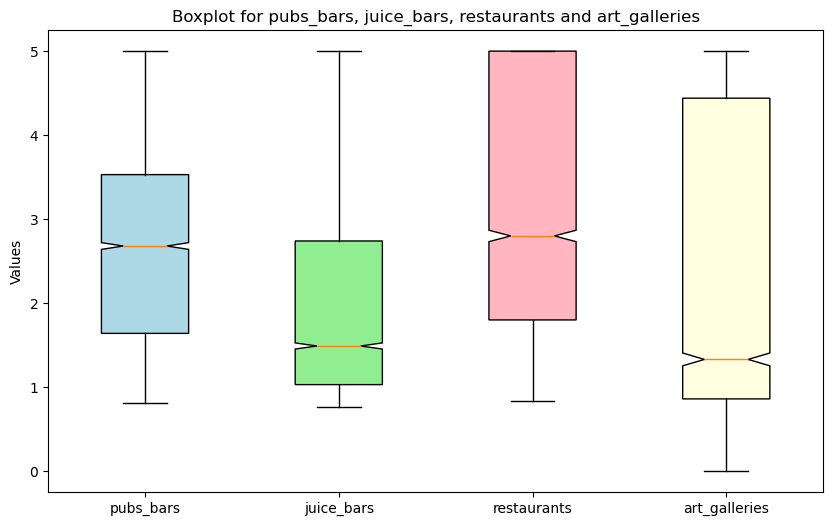

In [45]:
# Columns to plot
cols = ['pubs_bars', 'juice_bars', 'restaurants', 'art_galleries']

# Prepare figure
plt.figure(figsize=(10,6))

# Boxplot
box = plt.boxplot([df_review[col] for col in cols],
                  tick_labels=cols,
                  patch_artist=True,  # color the boxes
                  notch=True)  # show notches for median

# Customize colors
colors = ['lightblue', 'lightgreen', 'lightpink', 'lightyellow']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

plt.title("Boxplot for pubs_bars, juice_bars, restaurants and art_galleries")
plt.ylabel("Values")
plt.show()

#### Data Preparation

We are adding a few more columns and generating random data for these new columns. Later, we will enrich with contextual information from APIs and web sources to connect and make meaningful relations with our other sources, Web API, and HTML, in the following milestones.

#### Adding a date column in a DataFrame. This is review data when a traveler provided the review.

In [46]:
df_rn = df_review.copy()
# List of U.S. public holidays in 2025
public_holidays = [
    "2025-01-01", "2025-01-20", "2025-02-17", "2025-04-18",
    "2025-05-26", "2025-06-19", "2025-07-04", "2025-09-01",
    "2025-10-13", "2025-11-11", "2025-11-27", "2025-12-25"
]
public_holidays = pd.to_datetime(public_holidays)

# Generating all dates for 2025
start_date = datetime(2025, 1, 1)
end_date = datetime(2025, 12, 31)
all_dates = pd.date_range(start=start_date, end=end_date, freq='D')

# Get all Saturdays and Sundays
weekends = all_dates[all_dates.weekday >= 5]  # 5 = Saturday, 6 = Sunday

# Combine weekends and holidays
special_dates = pd.to_datetime(sorted(set(public_holidays).union(set(weekends))))

# Mixing special dates and other 2025 dates for diversity
def random_date():
    if np.random.rand() < 0.30:  # 30% chance of weekend/holiday
        return np.random.choice(special_dates)
    else:
        random_day = np.random.randint(0, (end_date - start_date).days)
        return start_date + timedelta(days=random_day)
        
df_rn["date"] = [random_date() for _ in range(len(df_review))]

# Marking dates are holidays or weekends
df_rn['is_weekend'] = df_rn['date'].dt.weekday >= 5
df_rn['is_holiday'] = df_rn['date'].isin(public_holidays)

# value counts for weekend and holidays
df_rn[['is_weekend', 'is_holiday']].value_counts()

is_weekend  is_holiday
False       False         2601
True        False         2584
False       True           271
Name: count, dtype: int64

#### We are adding a season column and value in the data frame.

In [47]:
# function to assign season
def get_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

# Apply the function to create a new column
df_rn['season'] = df_rn['date'].apply(get_season)

# value counts for seasons
df_rn['season'].value_counts()

season
Summer    1377
Spring    1369
Winter    1356
Fall      1354
Name: count, dtype: int64

#### Adding City columns and even distribution across cities

In [48]:
# We are considering only four for cities.
cities = ['Miami', 'New York', 'Santa Monica', 'Chicago']

# Adding the city column and random values.
df_rn['city'] = np.random.choice(cities, size=len(df_rn))

# value counts for seasons
df_rn['city'].value_counts()

city
New York        1419
Santa Monica    1386
Miami           1341
Chicago         1310
Name: count, dtype: int64

In [49]:
df_rn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5456 entries, 0 to 5455
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   user_id                5456 non-null   object        
 1   churches               5456 non-null   float64       
 2   resorts                5456 non-null   float64       
 3   beaches                5456 non-null   float64       
 4   parks                  5456 non-null   float64       
 5   theatres               5456 non-null   float64       
 6   museums                5456 non-null   float64       
 7   malls                  5456 non-null   float64       
 8   zoo                    5456 non-null   float64       
 9   restaurants            5456 non-null   float64       
 10  pubs_bars              5456 non-null   float64       
 11  local_services         5456 non-null   float64       
 12  burger_pizza_shops     5456 non-null   float64       
 13  hot

We do not see any NaN values.

In [50]:
# DataFrame after data cleaning, transformation and preparation with some random data.
df_rn.head()

,user_id,churches,resorts,beaches,parks,theatres,museums,malls,zoo,restaurants,pubs_bars,local_services,burger_pizza_shops,hotels_other_lodgings,juice_bars,art_galleries,dance_clubs,swimming_pools,gyms,bakeries,beauty_spas,cafes,view_points,monuments,gardens,date,is_weekend,is_holiday,season,city
0,User 1,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.35,2.33,2.64,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-07-20,True,False,Summer,Miami
1,User 2,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.64,2.33,2.65,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-06-15,True,False,Summer,Santa Monica
2,User 3,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-05-25,True,False,Spring,New York
3,User 4,0.0,0.5,3.63,3.63,5.0,2.92,5.0,2.35,2.33,2.64,1.73,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-12-25,False,True,Winter,Chicago
4,User 5,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-10-11,True,False,Fall,Miami


In [51]:
# save dataframe to a csv file.
df_rn.to_csv("df_google_review_ratings.csv")

### Ethical Considerations

The ethical considerations in handling the Travel Review Dataset primarily involve ensuring data privacy and maintaining integrity. This dataset is publicly available for research and learning.